In [23]:
import pandas as pd
import numpy as np
import io

In [24]:
df = pd.read_csv("retail_x_clientes.csv")
df.head()

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn
0,1860,50,23962.22,Ciudad de México,2023-08-30,4,5365.92,1.0
1,4772,49,NaN,puebla,2023-06-05,5,4692.15,1.0
2,4092,17,NaN,CDMX,2022-11-29,9,4617.36,1.0
3,1466,40,NaN,Puebla,2021-10-09,5,2101.78,0.0
4,5426,21,9998.37,Ciudad de México,2023-09-02,3,-1798.42,0.0


In [25]:
# Diagnóstico estructural
print("--- DIMENSIONES ---")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}\n")

print("--- INSPECCIÓN DE TIPOS DE DATOS ---")
df.info()

print("\n--- MUESTRA REGISTROS CRUDOS ---")
print(df.head(3))

--- DIMENSIONES ---
Filas: 10000, Columnas: 8

--- INSPECCIÓN DE TIPOS DE DATOS ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          10000 non-null  int64  
 1   edad                 10000 non-null  int64  
 2   ingresos             7000 non-null   float64
 3   ciudad               10000 non-null  str    
 4   fecha_ultima_compra  10000 non-null  str    
 5   num_compras          10000 non-null  int64  
 6   deuda                10000 non-null  float64
 7   churn                8999 non-null   float64
dtypes: float64(3), int64(3), str(2)
memory usage: 625.1 KB

--- MUESTRA REGISTROS CRUDOS ---
   customer_id  edad  ingresos            ciudad fecha_ultima_compra  \
0         1860    50  23962.22  Ciudad de México          2023-08-30   
1         4772    49       NaN            puebla          2023-06-05   
2         

In [26]:
# Mascara de detección de registros desplazados
mask_desplazados = ~df['fecha_ultima_compra'].str.contains(r'\d{2}/\d{2}/\d{4}', na=False)

print(f"Registros con columnas desplazadas detectados: {mask_desplazados.sum()}")
print("Muestra de filas desplazadas:")
print(df[mask_desplazados][['ciudad', 'fecha_ultima_compra', 'num_compras', 'deuda']])

Registros con columnas desplazadas detectados: 10000
Muestra de filas desplazadas:
                ciudad fecha_ultima_compra  num_compras    deuda
0     Ciudad de México          2023-08-30            4  5365.92
1               puebla          2023-06-05            5  4692.15
2                 CDMX          2022-11-29            9  4617.36
3               Puebla          2021-10-09            5  2101.78
4     Ciudad de México          2023-09-02            3 -1798.42
...                ...                 ...          ...      ...
9995              CDMX          2021-07-31            6  2035.49
9996              CDMX          2022-01-17            4  4674.32
9997       México D.F.          2021-02-10            1  6148.24
9998            Puebla          2021-10-30            2  3710.74
9999            Puebla          2024-02-24            6  2112.72

[10000 rows x 4 columns]


In [27]:
# 1. Conteo y Porcentaje de Valores Faltantes
nulos_diag = pd.DataFrame({
    'Nulos_Absolutos': df.isna().sum(),
    'Porcentaje_%': (df.isna().mean() * 100).round(2)
})
print("--- DIAGNÓSTICO DE VALORES FALTANTES ---")
print(nulos_diag)




--- DIAGNÓSTICO DE VALORES FALTANTES ---
                     Nulos_Absolutos  Porcentaje_%
customer_id                        0          0.00
edad                               0          0.00
ingresos                        3000         30.00
ciudad                             0          0.00
fecha_ultima_compra                0          0.00
num_compras                        0          0.00
deuda                              0          0.00
churn                           1001         10.01


In [28]:
# Identificando los grupos a los cuales pertenecen los valores nulos (Ciudad)
nulos_por_ciudad = df[df['ingresos'].isna()]['ciudad'].value_counts()
print("\n--- DISTRIBUCIÓN DE VALORES NULOS POR CIUDAD ---")
print(nulos_por_ciudad)


--- DISTRIBUCIÓN DE VALORES NULOS POR CIUDAD ---
ciudad
Puebla              616
Ciudad de México    571
CDMX                563
puebla              489
México D.F.         436
Guadalajara         325
Name: count, dtype: int64


In [29]:
# Identificando los grupos a los cuales pertenecen los valores nulos (Edad)
nulos_por_edad = df[df['ingresos'].isna()]['edad'].value_counts()
print("\n--- DISTRIBUCIÓN DE VALORES NULOS POR EDAD ---")
print(nulos_por_edad)


--- DISTRIBUCIÓN DE VALORES NULOS POR EDAD ---
edad
40    112
38    106
42    106
39    103
35     91
     ... 
75      1
79      1
74      1
9       1
0       1
Name: count, Length: 81, dtype: int64


In [30]:
# 2. Evaluación del Coeficiente de Asimetría (Skewness) para 'ingresos'
skew_ingresos = df['ingresos'].skew()
print(f"\nCoeficiente de Asimetría (Skewness) de 'ingresos': {skew_ingresos:.4f}")
skew_deuda = df['deuda'].skew()
print(f"Coeficiente de Asimetría (Skewness) de 'deuda': {skew_deuda:.4f}")


Coeficiente de Asimetría (Skewness) de 'ingresos': 0.0309
Coeficiente de Asimetría (Skewness) de 'deuda': 8.7652


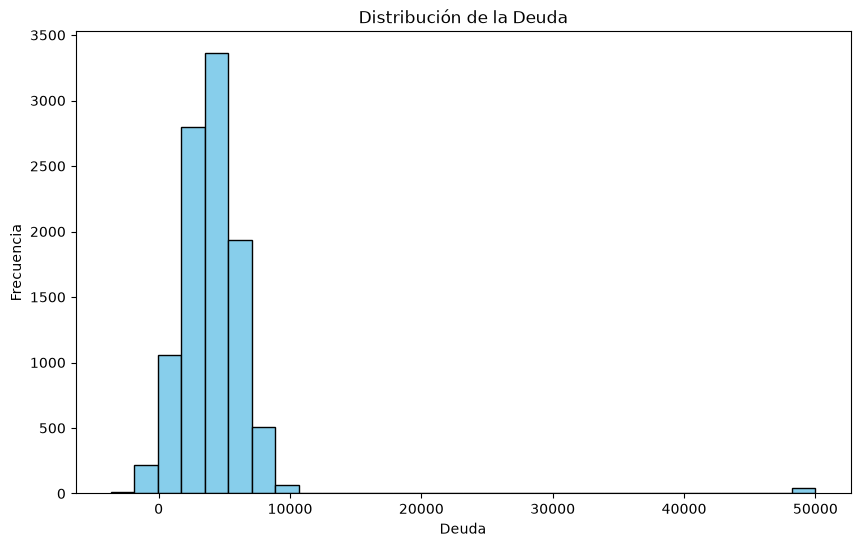

In [31]:
# Gráfica de distribución de la deuda
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['deuda'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribución de la Deuda')
plt.xlabel('Deuda')
plt.ylabel('Frecuencia')
plt.show()

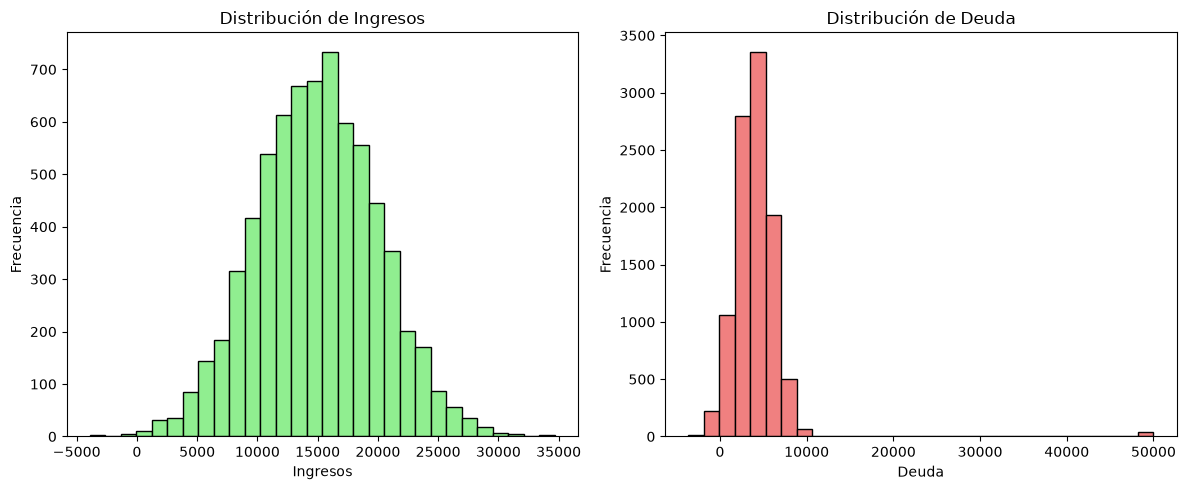

In [32]:
# Grafica de distribución de ingresos (subplot-1) y deuda (subplot-2) de tipo histograma y boxplot
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(df['ingresos'], bins=30, color='lightgreen', edgecolor='black')
plt.title('Distribución de Ingresos')
plt.xlabel('Ingresos')
plt.ylabel('Frecuencia')

plt.subplot(1, 2, 2)
plt.hist(df['deuda'], bins=30, color='lightcoral', edgecolor='black')
plt.title('Distribución de Deuda')
plt.xlabel('Deuda')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

In [33]:
print("--- CATEGORÍAS ÚNICAS EN 'ciudad' ANTES DE LIMPIAR ---")
print(df['ciudad'].value_counts(dropna=False))

--- CATEGORÍAS ÚNICAS EN 'ciudad' ANTES DE LIMPIAR ---
ciudad
Ciudad de México    1994
Puebla              1973
CDMX                1949
puebla              1576
México D.F.         1499
Guadalajara         1009
Name: count, dtype: int64


In [34]:
# 1. Mapeo de Estandarización y Corrección de Mojibake
mapeo_ciudades = {
    'Ciudad de MÃ©xico': 'CDMX',
    'MÃ©xico D.F.': 'CDMX',
    'Ciudad de México': 'CDMX',
    'puebla': 'Puebla'
}

df['ciudad'] = df['ciudad'].replace(mapeo_ciudades)

print("\n--- CATEGORÍAS ESTANDARIZADAS ---")
print(df['ciudad'].value_counts())





--- CATEGORÍAS ESTANDARIZADAS ---
ciudad
CDMX           3943
Puebla         3549
México D.F.    1499
Guadalajara    1009
Name: count, dtype: int64


In [35]:
# 2. Generación de Variables Indicadoras (Dummies)
df_dummies = pd.get_dummies(df['ciudad'], prefix='ciudad', dtype=int)
df = pd.concat([df, df_dummies], axis=1)

print("\nVariables binarias (dummies) integradas:")
print(df_dummies.head(3))


Variables binarias (dummies) integradas:
   ciudad_CDMX  ciudad_Guadalajara  ciudad_México D.F.  ciudad_Puebla
0            1                   0                   0              0
1            0                   0                   0              1
2            1                   0                   0              0


In [36]:
df

,customer_id,edad,ingresos,ciudad,fecha_ultima_compra,num_compras,deuda,churn,ciudad_CDMX,ciudad_Guadalajara,ciudad_México D.F.,ciudad_Puebla
0,1860,50,23962.22,CDMX,2023-08-30,4,5365.92,1.0,1,0,0,0
1,4772,49,NaN,Puebla,2023-06-05,5,4692.15,1.0,0,0,0,1
2,4092,17,NaN,CDMX,2022-11-29,9,4617.36,1.0,1,0,0,0
3,1466,40,NaN,Puebla,2021-10-09,5,2101.78,0.0,0,0,0,1
4,5426,21,9998.37,CDMX,2023-09-02,3,-1798.42,0.0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,5931,43,14059.39,CDMX,2021-07-31,6,2035.49,0.0,1,0,0,0
9996,2691,31,9851.20,CDMX,2022-01-17,4,4674.32,1.0,1,0,0,0
9997,5550,15,17832.33,México D.F.,2021-02-10,1,6148.24,1.0,0,0,1,0
9998,5408,44,13644.92,Puebla,2021-10-30,2,3710.74,1.0,0,0,0,1


In [37]:
print("Tipo de dato de 'fecha_ultima_compra':", df['fecha_ultima_compra'].dtype)
print("Muestra de fechas:", df['fecha_ultima_compra'].head(3).tolist())

Tipo de dato de 'fecha_ultima_compra': str
Muestra de fechas: ['2023-08-30', '2023-06-05', '2022-11-29']


## 5. Parseo y Extracción de Variables Temporales

In [38]:
# 1. Parseo a datetime64
df['fecha_ultima_compra'] = pd.to_datetime(df['fecha_ultima_compra'], format='%Y-%m-%d')



In [39]:

# 2. Extracción de componentes temporales
df['año_compra'] = df['fecha_ultima_compra'].dt.year
df['mes_compra'] = df['fecha_ultima_compra'].dt.month



In [40]:
# 3. Cálculo de Recencia (Días transcurridos a la fecha de corte 01/04/2024)
fecha_corte = pd.to_datetime('2024-04-01')
df['recencia_dias'] = (fecha_corte - df['fecha_ultima_compra']).dt.days

print("\n--- NUEVAS VARIABLES TEMPORALES ---")
print(df[['fecha_ultima_compra', 'año_compra', 'mes_compra', 'recencia_dias']].head(3))


--- NUEVAS VARIABLES TEMPORALES ---
  fecha_ultima_compra  año_compra  mes_compra  recencia_dias
0          2023-08-30        2023           8            215
1          2023-06-05        2023           6            301
2          2022-11-29        2022          11            489


## Fase 6: Diagnóstico y Tratamiento de Outliers e Inconsistencias Numéricas

In [41]:
# 1. Diagnóstico de Inconsistencias de Signo
print(f"Deudas negativas: {(df['deuda'] < 0).sum()}")
print(f"Ingresos negativos: {(df['ingresos'] < 0).sum()}")

Deudas negativas: 243
Ingresos negativos: 10


In [42]:
# 2. Diagnóstico de Outliers mediante IQR en 'ingresos'
Q1_ing = df['ingresos'].quantile(0.25)
Q3_ing = df['ingresos'].quantile(0.75)
IQR_ing = Q3_ing - Q1_ing

LI_ing = Q1_ing - 1.5 * IQR_ing
LS_ing = Q3_ing + 1.5 * IQR_ing

outliers_count = ((df['ingresos'] < LI_ing) | (df['ingresos'] > LS_ing)).sum()
print(f"\n[Ingresos] Q1={Q1_ing:.2f}, Q3={Q3_ing:.2f}, IQR={IQR_ing:.2f}")
print(f"[Ingresos] Límite Superior (LS): {LS_ing:.2f}")
print(f"[Ingresos] Outliers detectados: {outliers_count}")


[Ingresos] Q1=11479.54, Q3=18393.65, IQR=6914.10
[Ingresos] Límite Superior (LS): 28764.80
[Ingresos] Outliers detectados: 41


In [43]:
# 3. Diagnóstico de Outliers mediante IQR en 'deuda'
Q1_deuda = df['deuda'].quantile(0.25)
Q3_deuda = df['deuda'].quantile(0.75)
IQR_deuda = Q3_deuda - Q1_deuda

LI_deuda = Q1_deuda - 1.5 * IQR_deuda
LS_deuda = Q3_deuda + 1.5 * IQR_deuda

outliers_count = ((df['deuda'] < LI_deuda) | (df['deuda'] > LS_deuda)).sum()
print(f"\n[Deuda] Q1={Q1_deuda:.2f}, Q3={Q3_deuda:.2f}, IQR={IQR_deuda:.2f}")
print(f"[Deuda] Límite Superior (LS): {LS_deuda:.2f}")
print(f"[Deuda] Outliers detectados: {outliers_count}")


[Deuda] Q1=2622.23, Q3=5333.20, IQR=2710.97
[Deuda] Límite Superior (LS): 9399.65
[Deuda] Outliers detectados: 102


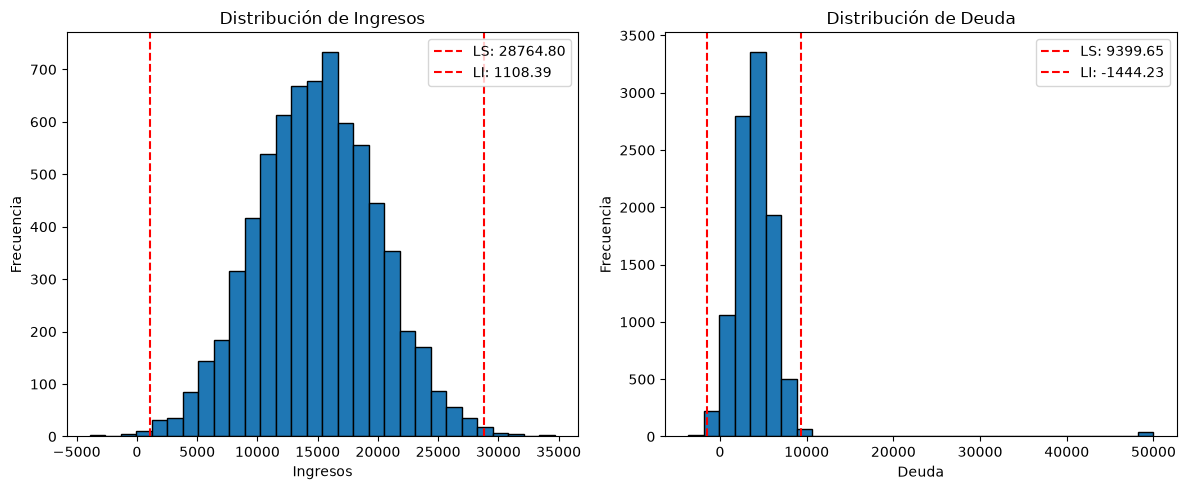

In [44]:
# Grafica de distribución de ingresos (subplot-1) y deuda (subplot-2) de tipo histograma con limites de outliers
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(df['ingresos'], bins=30, edgecolor='black')
plt.xlabel('Ingresos')
plt.ylabel('Frecuencia')
plt.title('Distribución de Ingresos')
plt.axvline(LS_ing, color='r', linestyle='--', label=f'LS: {LS_ing:.2f}')
plt.axvline(LI_ing, color='r', linestyle='--', label=f'LI: {LI_ing:.2f}')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(df['deuda'], bins=30, edgecolor='black')
plt.xlabel('Deuda')
plt.ylabel('Frecuencia')
plt.title('Distribución de Deuda')
plt.axvline(LS_deuda, color='r', linestyle='--', label=f'LS: {LS_deuda:.2f}')
plt.axvline(LI_deuda, color='r', linestyle='--', label=f'LI: {LI_deuda:.2f}')
plt.legend()

plt.tight_layout()
plt.show()